# Primes as atoms: factor trees and the sieve of Eratosthenes

*A companion notebook to* **Prime Numbers and the Riemann Hypothesis** *by Barry Mazur and William Stein (Cambridge University Press, 2016), Part I, chapters "What are prime numbers?", "Named prime numbers" and "Sieves".*

> *Primes as atoms.* To begin from the beginning, think of the operation of multiplication as a bond that ties numbers together: the equation $2\times 3 = 6$ invites us to imagine the number $6$ as (a molecule, if you wish) built out of its smaller constituents $2$ and $3$. … the numbers $2$ and $3$, then, are the indecomposable entities (atoms, if you wish) that comprise our number.

A **prime number** is a whole number bigger than $1$ that cannot be factored into a product of two smaller whole numbers. In this notebook you will:

1. draw **factor trees** for any number, and see that every tree for a number ends in the same primes;
2. run **Euclid's argument** that there are infinitely many primes, as a machine that keeps producing new ones;
3. **sieve** out the primes the way Eratosthenes did, one prime at a time.

Every picture has controls: change them and it redraws.

## 1. Factor trees

To factor $n$, split it as a product $n = d \times (n/d)$ of two smaller numbers, then keep splitting each factor until every factor is prime. Primes are drawn in red, composite numbers in dark blue. The book's figures use this code, here brought up to date.

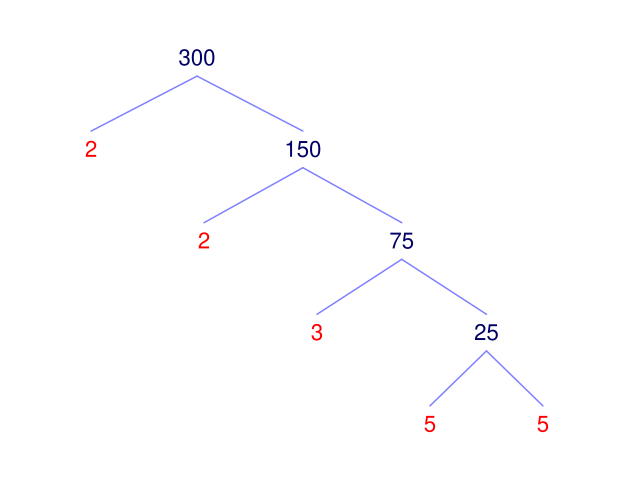

In [1]:
def factor_tree(n, sort=True):
    "A factor tree of n as nested pairs: a prime is a leaf; a composite k is (k, [left subtree, right subtree])."
    if is_prime(n):
        return (n, [])
    proper = divisors(n)[1:-1]
    d = proper[0] if sort else proper[randint(0, len(proper) - 1)]
    return (n, [factor_tree(d, sort), factor_tree(n // d, sort)])

def plot_factor_tree(n, sort=True, fontsize=16):
    "A picture of a factor tree of n: primes in red, composite numbers in dark blue."
    parts = []
    leaves = [0]                   # the next free leaf position, left to right
    depth = [0]

    def place(node, level):
        "Draw the subtree; return the x of its root (leaves left to right, a parent centred over its children)."
        k, children = node
        depth[0] = max(depth[0], level)
        if children:
            xs = [place(child, level + 1) for child in children]
            x = sum(xs) / len(xs)
            for cx in xs:
                parts.append(line([(x, -level - 0.2), (cx, -level - 0.8)], color=(0.5, 0.5, 1)))
        else:
            x = leaves[0]
            leaves[0] += 1
        color = 'red' if is_prime(k) else (0, 0, 0.4)
        parts.append(text('$%s$' % k, (x, -level), color=color, fontsize=fontsize))
        return x

    place(factor_tree(n, sort), 0)
    # (two invisible corner points leave room around the labels, which are drawn at points and would be clipped)
    parts.append(point([(-0.7, -depth[0] - 0.5), (leaves[0] - 0.3, 0.5)], size=0, alpha=0))
    g = sum(parts)
    g.axes(False)
    return g

plot_factor_tree(300)

Try other numbers below. With **random splits**, each redraw makes a different tree, but the primes at the bottom are always the same: that is the **fundamental theorem of arithmetic** (every whole number bigger than $1$ factors as a product of primes in exactly one way, up to order).

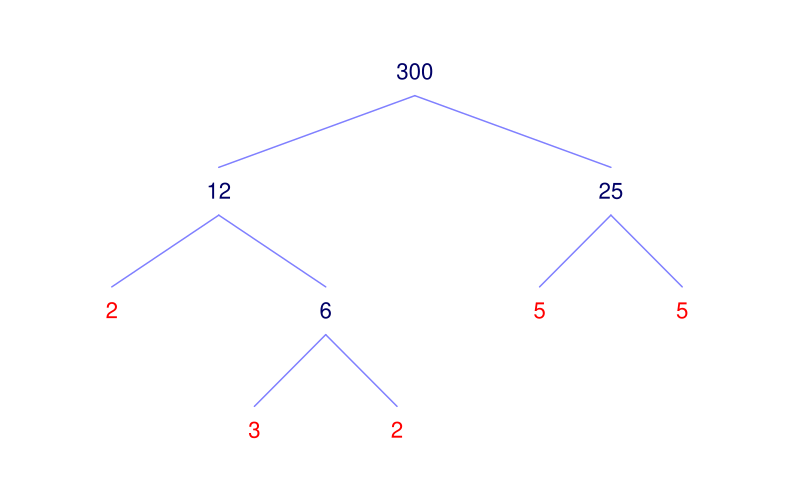

300 = 2^2 * 3 * 5^2


In [2]:
@interact
def trees(n=input_box(300, label='n'), random_splits=checkbox(True, label='random splits'),
          redraw=selector(['draw again'], buttons=True, label='')):
    n = Integer(n)
    if n < 2 or n > 10^12:
        print('Choose n between 2 and 10^12.')
        return
    show(plot_factor_tree(n, sort=not random_splits), figsize=[8, 5])
    print('%s = %s' % (n, factor(n)))

The book's largest tree is for $6469693230 = 2\cdot 3\cdot 5\cdot 7\cdot 11\cdot 13\cdot 17\cdot 19\cdot 23\cdot 29$, the product of the primes up to $29$:

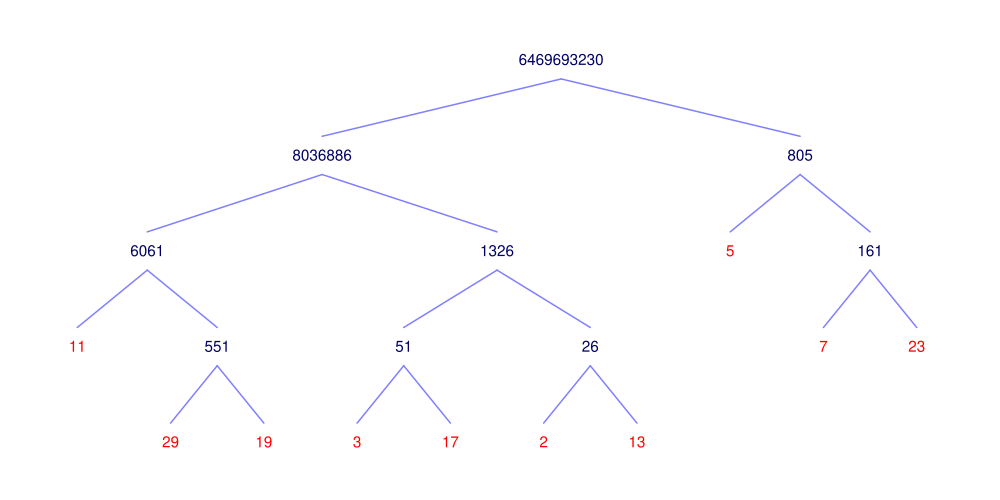

In [3]:
show(plot_factor_tree(prod(prime_range(30)), sort=False, fontsize=11), figsize=[10, 5])

## 2. A machine that makes new primes

Euclid's proof that there are infinitely many primes is really a recipe. Start with a bag of primes, say $\{2\}$. Multiply everything in the bag together and add $1$. The result is not divisible by any prime in the bag (it leaves remainder $1$), so each of its prime factors is a **new** prime: put them in the bag and repeat. The bag can never be complete.

The book runs this recipe and remarks that the bag grows explosively: the numbers to factor quickly have dozens of digits. Step by step:

In [4]:
def bag_of_primes(steps):
    "Euclid's recipe, `steps` times, starting from the bag {2}."
    bag = [2]
    for step in range(steps):
        N = prod(bag) + 1
        new = prime_divisors(N)
        print('step %d: %s + 1 = %s = %s, new primes %s' % (step + 1, ' * '.join(map(str, bag)) if len(bag) < 6 else 'product of the bag', N, factor(N), new))
        bag += new
    return bag

@interact
def euclid(steps=slider(1, 6, 1, 4, label='steps')):
    bag = bag_of_primes(steps)
    print()
    print('the bag now holds %d primes: %s' % (len(bag), sorted(bag)))

step 1: 2 + 1 = 3 = 3, new primes [3]
step 2: 2 * 3 + 1 = 7 = 7, new primes [7]
step 3: 2 * 3 * 7 + 1 = 43 = 43, new primes [43]
step 4: 2 * 3 * 7 * 43 + 1 = 1807 = 13 * 139, new primes [13, 139]

the bag now holds 6 primes: [2, 3, 7, 13, 43, 139]


(Step 7 already needs to factor a number with about 26 digits, and the book notes that a later step took a day of specialised factoring.)

## 3. The sieve of Eratosthenes

> Eratosthenes, the mathematician from Cyrene (and later, librarian at Alexandria) explained how to *sift* the prime numbers from the series of all numbers …

Circle $2$ and cross out its other multiples; circle the next number not crossed out ($3$) and cross out its multiples; and so on. Below, the prime being used is red, its multiples that this step crosses out are dark grey, the numbers crossed out earlier are white, and the ones still in play are light grey. Move the slider to sieve with $2$, then $3$, $5$, $7$, …

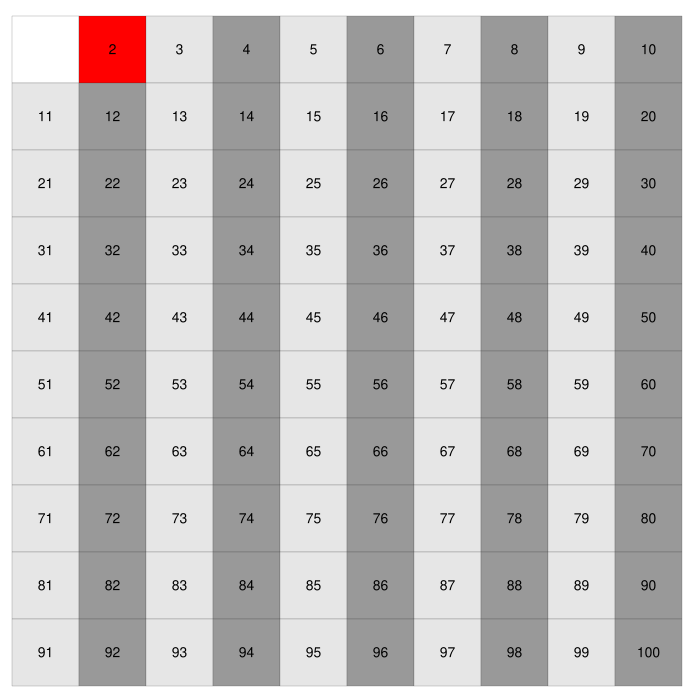

after sieving with the primes up to 2, 50 numbers are left


In [5]:
def sieve_step(p, n, gone=(1, 1, 1), prime=(1, 0, 0), multiple=(0.6, 0.6, 0.6), remaining=(0.9, 0.9, 0.9), fontsize=10):
    "The grid of 1..n (n a square) after sieving with the primes up to p, the multiples of p highlighted."
    side = isqrt(n)
    exclude = prod(prime_range(p))       # the primes before p
    g = Graphics()
    for k in range(1, n + 1):
        if k <= p and is_prime(k):
            c = prime
        elif k == 1 or (gcd(k, exclude) != 1 and not is_prime(k)):
            c = gone
        elif k % p == 0:
            c = multiple
        else:
            c = remaining
        i, j = (k - 1) % side, side - 1 - (k - 1) // side
        g += polygon([(i, j), (i + 1, j), (i + 1, j + 1), (i, j + 1)], color=c, edgecolor=(0.2, 0.2, 0.2), thickness=0.2)
        if c != gone:
            g += text(str(k), (i + 0.5, j + 0.5), color='black', fontsize=fontsize)
    g.axes(False)
    g.set_aspect_ratio(1)
    return g

@interact
def sieve(n=selector([100, 144, 225, 400], default=100, label='numbers up to'),
          p=slider([2, 3, 5, 7, 11, 13, 17, 19], default=2, label='sieve with prime')):
    show(sieve_step(p, n, fontsize=10 if n <= 144 else 7), figsize=[7, 7])
    left = [k for k in range(2, n + 1) if all(k == q or k % q for q in prime_range(p + 1))]
    print('after sieving with the primes up to %d, %d numbers are left' % (p, len(left)))

Notice how soon the sieve is finished: for numbers up to $100$, after sieving with $2$, $3$, $5$ and $7$ everything left is prime. The reason is that a composite number $n$ always has a prime factor at most $\sqrt{n}$, so to find the primes up to $N$ you only ever need the primes up to $\sqrt{N}$. (Up to $100$, sieving with $2$, $3$ and $5$ already decides everything except $49$, $77$ and $91$.)

The sieve is also how computers list primes today. Here are the counts it gives:

In [6]:
for N in [10, 100, 1000, 10^4, 10^5, 10^6]:
    print('%8d primes up to %d' % (len(prime_range(N + 1)), N))

       4 primes up to 10
      25 primes up to 100
     168 primes up to 1000
    1229 primes up to 10000
    9592 primes up to 100000
   78498 primes up to 1000000


How fast those counts grow, and how well we can predict them, is the subject of the rest of the book (and of the next notebook).

## Things to try

1. Find a number with at least three different factor trees that look completely different. Do they always have the same *depth*?
2. In Euclid's recipe, is $\prod(\text{bag}) + 1$ ever itself prime? For which steps?
3. Change `sieve_step` so that it also marks, for each crossed-out number, the prime that crossed it out first. Which prime crosses out the most numbers up to $400$?

---
*Adapted and expanded from the code that drew the figures in* Prime Numbers and the Riemann Hypothesis *(Barry Mazur and William Stein, Cambridge University Press, 2016); quotations are from the book. MIT license. Runs in the browser with [Sagebrush](https://sagebrush.space).*